In [80]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import numpy as np

In [ ]:
# from multi_tile_layout-3.0.40_fsd_v3.yaml
PITCH = 0.372
TILE_X = 47.1055

COORDS = [('z', 'y'),  # 1st panel
          ('x', 'y'),  # 2nd
          ('x', 'z')]  # 3rd

LIMITS = [(43, 47.5),                # x
          (-1, 1),                   # y
          (-2, 2)]                   # z

INPUT_DIR = 'data/edep-sim'

def limits_for(coord_name):
    icoord = ['x', 'y', 'z'].index(coord_name)
    return LIMITS[icoord]

def draw_pixel(i_panel, ax):
    if i_panel == 0:
        pixel = Rectangle((0, 0), PITCH, PITCH,
                          facecolor='none', edgecolor='black')
        ax.add_patch(pixel)
    else:
        pixel = Line2D([TILE_X, TILE_X], [0, PITCH], color='black')
        ax.add_line(pixel)

def plot_edeps(name):
    with h5py.File(f'{INPUT_DIR}/{name}.hdf5') as f:
        segs = f['segments'][:]
    fig, axs = plt.subplots(1, 3, figsize=(20, 7))
    for i, ax in enumerate(axs):
        a, b = COORDS[i]
        u, u1, u2 = segs[a], segs[f'{a}_start'], segs[f'{a}_end']
        v, v1, v2 = segs[b], segs[f'{b}_start'], segs[f'{b}_end']
        line_segs = np.stack([np.column_stack([u1, v1]),
                              np.column_stack([u2, v2])],
                             axis=1)
        lc = LineCollection(line_segs)
        ax.add_collection(lc)
        ax.scatter(u, v, color='C0', s=10)
        draw_pixel(i, ax)
        ax.set_xlim(limits_for(a))
        ax.set_ylim(limits_for(b))
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlabel(f'{a} [cm]')
        ax.set_ylabel(f'{b} [cm]')
    fig.suptitle(name)

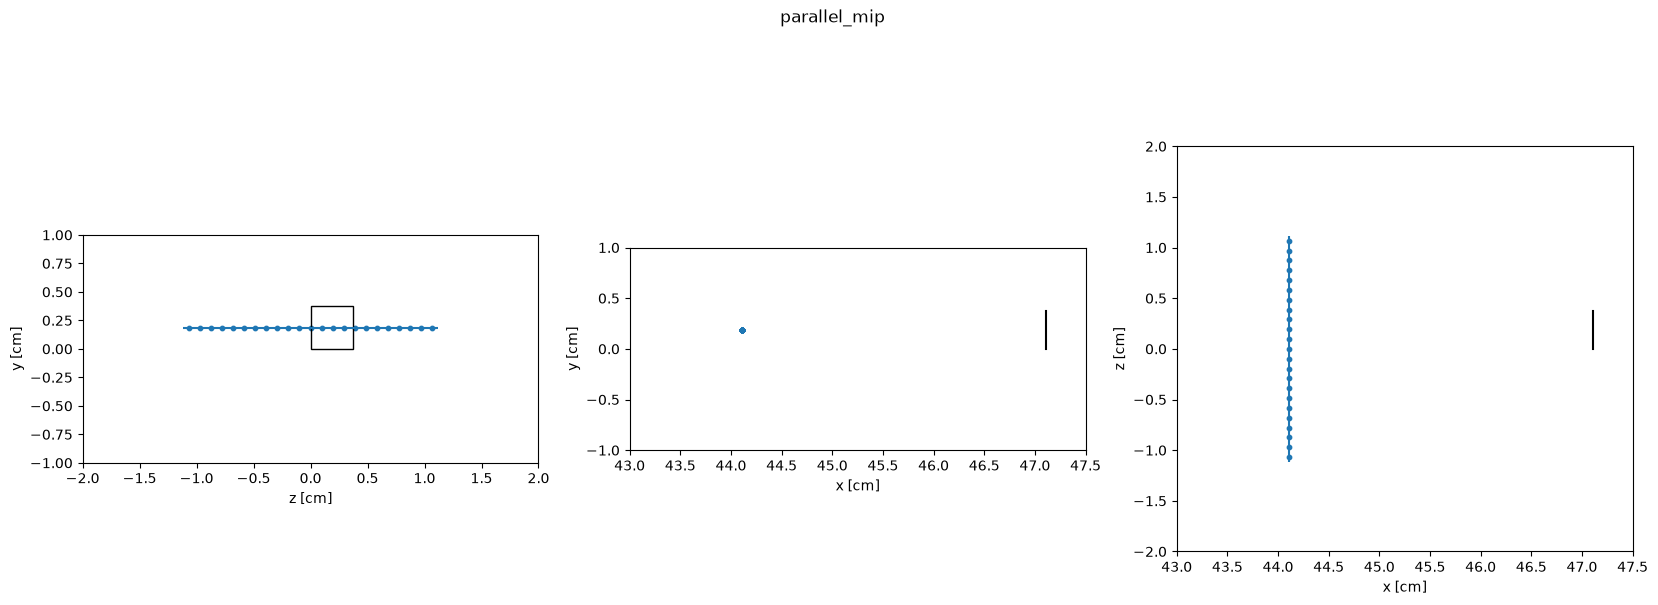

In [84]:
for h5f in Path(INPUT_DIR).glob('*.hdf5'):
    plot_edeps(h5f.stem)
    # plt.show()